# Question 6 (ML): Predicting Listing Prices of Unseen DDR5 and NVMe Products

**Owner:** Mã Đức Khải
**Task Type:** Supervised Machine Learning (Regression with Group-based Splitting)

---

## 1. Question Formulation, Motivation & Data Leakage Control

### 1.1. Research Question
> **Can we predict the listing price (`price_amount`, in USD) of unseen DDR5 and NVMe products from hardware attributes extracted at prediction time (`series_id`, `capacity_gb`, `brand`, `kit_modules`, `form_factor`, `speed_mhz`, `cas_latency`, `pcie_gen`, `has_rgb`), what is the percentage error reduction compared to a category-capacity baseline, which specifications drive hardware prices the most, and do market location (`geography_id`) or observation date (`observed_date`) add meaningful predictive value?**

### 1.2. Motivation & Target Users
* **Consumers & PC Builders:** Need an objective fair-price benchmark to evaluate whether a newly listed RAM kit or NVMe SSD is reasonably priced or inflated given its hardware specs.
* **E-commerce Pricing Analysts:** Need an automated cold-start pricing model when cataloging unseen SKUs (`product_name` not yet in historical logs) across regional ZIP markets.
* **Target Variable Choice (`log(price_amount)`):** Hardware prices are strictly positive and right-skewed across capacities (ranging from budget 8GB DDR5 modules to 4TB enterprise PCIe Gen5 SSDs). Modeling $y = \ln(\text{price\_amount})$ stabilizes error variance across price tiers and aligns log-scale MAE/RMSE with relative percentage errors.

### 1.3. Feature Audit & Data Leakage Prevention
To ensure the model generalizes to **unseen products** at listing time, every column in the dataset is audited for availability and leakage prior to modeling:

| Column / Feature | Status in ML | Justification & Leakage Prevention |
| :--- | :--- | :--- |
| `price_amount` | **Target ($y$)** | Transformed as `log_price = np.log(price_amount)`. |
| `normalized_price_amount` | **EXCLUDED (Leakage)** | Computed directly from `price_amount / quantity_value`. Including it leaks the target variable. |
| `price_per_unit_recomputed` | **EXCLUDED (Leakage)** | Recomputed unit price from `src/cleaning.py`; excluded for the same target leakage reason. |
| `product_name` | **Grouping Key ONLY** | Used to parse technical specs (`src/parse_titles.py`) and as the `groups` key in `GroupShuffleSplit` / `GroupKFold` so identical products never span both train and test sets. Raw text is dropped before fitting. |
| `quantity_name`, `quantity_value`, `quantity_unit` | **Transformed -> `capacity_gb`** | Standardized into a single numerical feature `capacity_gb` (converting `terabytes` $\times 1000 \to$ `gigabytes` to match the dataset's normalization rule) plus `log_capacity_gb`. |
| `series_id`, `brand`, `form_factor`, `kit_modules`, `speed_mhz`, `cas_latency`, `pcie_gen`, `has_rgb` | **Core Hardware Features ($X_{\text{core}}$)** | Known hardware specifications available at product launch/listing time. Structural missing values (e.g., `speed_mhz` for NVMe, `pcie_gen` for DDR5) are imputed inside the scikit-learn `Pipeline`. |
| `geography_id`, `observed_date` | **Ablation Features ($X_{\text{context}}$)** | Held out from the core hardware model, then tested in an ablation study to quantify whether US ZIP market or daily fluctuations improve predictions. |

---

## 2. Data Preprocessing & Feature Extraction Workflow

Before splitting the data, we apply the shared cleaning and parsing rules from `src/cleaning.py` and `src/parse_titles.py`:
1. **Load raw dataset:** Read the 10 core columns from `data/raw/ddr5-and-nvme-prices-2026-07-21-to-2026-08-18.csv` with `geography_id` preserved as string.
2. **Flag & remove category noise (`is_noise`):** Exclude the 17 complete PC/laptop rows (`is_system_noise`) and 11 diskless NAS appliance rows (`is_nas_noise`) mixed into the DDR5 category, as they are full systems rather than memory/storage components.
3. **Remove unresolved capacities (`is_unresolved`):** Exclude rows where `quantity_value == 0` or `quantity_unit == 'unknown'` because capacity is a fundamental physical determinant of RAM/SSD pricing.
4. **Extract hardware attributes (`add_parsed_features`):** Parse `brand`, `kit_modules`, `form_factor`, `speed_mhz`, `cas_latency`, `pcie_gen`, and `has_rgb` from unique product titles without touching price columns.
5. **Standardize capacity & target:** Compute `capacity_gb` (in GB for both DDR5 and NVMe) and target `log_price = np.log(price_amount)`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add project root so we can import reusable modules from src/
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.cleaning import RowLog, add_flags, analysis_view
from src.parse_titles import add_parsed_features

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 30)

In [2]:
# Locate raw CSV (supports both data/raw/ and current working directory)
RAW_CSV_Candidates = [
    PROJECT_ROOT / "data" / "raw" / "ddr5-and-nvme-prices-2026-07-21-to-2026-08-18.csv",
    PROJECT_ROOT / "ddr5-and-nvme-prices-2026-07-21-to-2026-08-18.csv",
]
RAW_CSV_PATH = next(p for p in RAW_CSV_Candidates if p.exists())

# 1. Initialize RowLog and load raw data
log = RowLog()
df_raw = pd.read_csv(RAW_CSV_PATH, dtype={"geography_id": str})
df_step = log.note(df_raw, "1. Load raw CSV", reason="Initial dataset (10 core columns)")

# 2. Add quality flags (is_unresolved, is_system_noise, is_nas_noise, is_noise)
df_step = add_flags(df_step)
df_step = log.note(
    df_step,
    "2. Add quality flags (src/cleaning.py)",
    reason="Flag unresolved capacity, complete PC/laptop noise (17 rows), and NAS noise (11 rows)",
)

# 3 & 4. Filter out system/NAS noise and unresolved capacity rows
df_clean = analysis_view(df_step, log=log, drop_unresolved=True, drop_noise=True)

# 5. Parse hardware attributes from product_name via src/parse_titles.py
df_ml = add_parsed_features(df_clean)
df_ml = log.note(
    df_ml,
    "5. Extract hardware attributes (src/parse_titles.py)",
    reason="Parse brand, kit_modules, form_factor, speed_mhz, cas_latency, pcie_gen, has_rgb",
)

# 6. Standardize capacity into gigabytes (1 TB = 1000 GB, matching cleaning.py convention) and create target
df_ml["capacity_gb"] = np.where(
    df_ml["quantity_unit"] == "terabytes",
    df_ml["quantity_value"].astype(float) * 1000.0,
    df_ml["quantity_value"].astype(float),
)
df_ml["log_capacity_gb"] = np.log(df_ml["capacity_gb"])
df_ml["log_price"] = np.log(df_ml["price_amount"].astype(float))

# Temporal feature (day index 0..28) for the later context ablation check
df_ml["observed_date_dt"] = pd.to_datetime(df_ml["observed_date"])
df_ml["day_index"] = (df_ml["observed_date_dt"] - df_ml["observed_date_dt"].min()).dt.days

print("\n=== ROW COUNT AUDIT TABLE ===")
display(log.table())

# Summary of extracted features & missingness by product category
CORE_FEATURES = [
    "series_id", "capacity_gb", "log_capacity_gb", "brand",
    "form_factor", "kit_modules", "speed_mhz", "cas_latency", "pcie_gen", "has_rgb"
]

summary_stats = []
for series, grp in df_ml.groupby("series_id"):
    row_info = {
        "series_id": series,
        "n_rows": len(grp),
        "n_unique_products": grp["product_name"].nunique(),
        "price_median_usd": grp["price_amount"].median(),
        "price_iqr_usd": grp["price_amount"].quantile(0.75) - grp["price_amount"].quantile(0.25),
    }
    for col in ["speed_mhz", "cas_latency", "pcie_gen"]:
        row_info[f"{col}_missing_%"] = round(grp[col].isna().mean() * 100, 2)
    summary_stats.append(row_info)

print("\n=== DATASET & FEATURE MISSINGNESS SUMMARY BY CATEGORY ===")
display(pd.DataFrame(summary_stats))

[1. Load raw CSV] 127,843 -> 127,843 rows (removed 0)
[2. Add quality flags (src/cleaning.py)] 127,843 -> 127,843 rows (removed 0)
[drop complete-system / NAS rows (DDR5 category noise)] 127,843 -> 127,815 rows (removed 28)
[drop unresolved capacity] 127,815 -> 123,475 rows (removed 4,340)
[5. Extract hardware attributes (src/parse_titles.py)] 123,475 -> 123,475 rows (removed 0)

=== ROW COUNT AUDIT TABLE ===


,step,rows_before,rows_after,rows_removed,reason
0,1. Load raw CSV,127843,127843,0,Initial dataset (10 core columns)
1,2. Add quality flags (src/cleaning.py),127843,127843,0,"Flag unresolved capacity, complete PC/laptop n..."
2,drop complete-system / NAS rows (DDR5 category...,127843,127815,28,laptop/desktop/mini-PC and NAS listings are no...
3,drop unresolved capacity,127815,123475,4340,"quantity unknown -> normalised price blank, ca..."
4,5. Extract hardware attributes (src/parse_titl...,123475,123475,0,"Parse brand, kit_modules, form_factor, speed_m..."



=== DATASET & FEATURE MISSINGNESS SUMMARY BY CATEGORY ===


,series_id,n_rows,n_unique_products,price_median_usd,price_iqr_usd,speed_mhz_missing_%,cas_latency_missing_%,pcie_gen_missing_%
0,ddr5_memory,18622,221,479.99,425.00,0.0,0.52,100.00
1,nvme_ssd,104853,907,169.99,188.98,100.0,100.00,10.61


### 2.1. Feature Refinement (row-wise rules, applied before the split)

Two small refinements are needed before modeling. Both are deterministic **row-wise** transformations of the product title / capacity (no statistics are computed across rows), so applying them before the train/test split cannot leak information:

1. **Generic (unbranded) listings → `brand_clean = "GENERIC"`.** `extract_brand()` takes the first token of the title. About 100 titles have no brand at all and start with the capacity or a generic word (e.g. *"1TB M.2 NVMe SSD 2280, PCIe Gen3 ..."*), which produced fake brands such as `1TB`, `512GB`, `M.2`, `SSD`. These are grouped into one `GENERIC` level because "no brand in the title" is itself a meaningful price signal (white-label products). A few Samsung OEM drives whose title starts with the part number (`PM9A3 ...`, `MZ-ALQ256B ...`) are mapped back to `SAMSUNG`.
2. **Interaction `log_cap_x_ddr5 = log_capacity_gb × 1[DDR5]`.** The price-vs-capacity slope differs between RAM and SSDs. Tree models learn this automatically, but the linear model (Ridge) needs the interaction term to allow a separate capacity slope per category.

Raw `capacity_gb` is **not** used as a model input next to `log_capacity_gb` (the two carry identical information, which would split the permutation importance of capacity between two columns). It is kept in the data only for the baseline and error analysis.

In [3]:
# (1) Titles without a brand: first token is a capacity ("1TB", "512GB") or a generic word
GENERIC_TOKENS = {"M.2", "SSD", "NVME", "INTERNAL"}
is_generic = df_ml["brand"].str.match(r"^[\d\W]") | df_ml["brand"].isin(GENERIC_TOKENS)
df_ml["brand_clean"] = np.where(is_generic, "GENERIC", df_ml["brand"])
# Samsung OEM drives whose title starts with the part number (e.g. "PM9A3 ...", "MZ-ALQ256B ...")
is_samsung_pn = df_ml["brand_clean"].str.match(r"^(?:PM9|MZ-)")
df_ml.loc[is_samsung_pn, "brand_clean"] = "SAMSUNG"

# (2) Category-specific capacity slope for the linear model
df_ml["log_cap_x_ddr5"] = df_ml["log_capacity_gb"] * (df_ml["series_id"] == "ddr5_memory").astype(float)

# has_rgb as a string category so every encoder treats it identically
df_ml["has_rgb"] = df_ml["has_rgb"].astype(str)

df_ml = log.note(
    df_ml,
    "6. Refine features (brand_clean, log_cap_x_ddr5)",
    reason="Row-wise only: map brandless titles to GENERIC, add capacity x category interaction",
)

print("Unique titles re-labelled as GENERIC:", df_ml.loc[is_generic, "product_name"].nunique())
display(
    df_ml.loc[is_generic].drop_duplicates("product_name")["brand"].value_counts().rename("n_titles").to_frame().T
)
print("Distinct brands before / after:", df_ml["brand"].nunique(), "/", df_ml["brand_clean"].nunique())

[6. Refine features (brand_clean, log_cap_x_ddr5)] 123,475 -> 123,475 rows (removed 0)
Unique titles re-labelled as GENERIC: 98


brand,1TB,M.2,256GB,512GB,SSD,2TB,128GB,4TB,16GB,NVME,980,INTERNAL
n_titles,22,16,15,15,12,8,3,3,1,1,1,1


Distinct brands before / after: 122 / 108


---

## 3. Group-Based Train/Test Split & Cross-Validation Design

### Why Standard Random Splitting Fails Here (Entity Leakage)
Although our cleaned dataset contains **123,475 observations**, these represent repeated daily price logs across 12 US ZIP markets for only **1,128 unique products (`product_name`)**. A standard random `train_test_split` would place different daily/ZIP observations of the **exact same product** into both the training and test sets, causing severe entity leakage and artificially inflating test performance.

### Splitting Strategy
1. **Hold-out Test Split (`GroupShuffleSplit`):** We partition unique products (`groups = df_ml["product_name"]`) using an 80/20 split (`test_size=0.20, random_state=42`). Exactly **20% of unique products (226 unseen products)** are locked away in the test set and evaluated **only once** at the end.
2. **Cross-Validation (`GroupKFold`):** For model comparison and hyperparameter tuning on the training set (902 unique products), we use 5-fold `GroupKFold(n_splits=5)` grouped by `product_name` so validation folds always evaluate generalization to unseen products.

In [4]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold

# Define feature sets:
# 1) Core hardware features (available purely from product specifications)
NUMERIC_CORE = ["log_capacity_gb", "log_cap_x_ddr5", "kit_modules", "speed_mhz", "cas_latency", "pcie_gen"]
CATEGORICAL_CORE = ["series_id", "brand_clean", "form_factor", "has_rgb"]
FEATURES_CORE = NUMERIC_CORE + CATEGORICAL_CORE

# 2) Extended features (adding ZIP market and observation day for the ablation study)
FEATURES_WITH_CONTEXT = FEATURES_CORE + ["geography_id", "day_index"]

TARGET_COL = "log_price"
GROUP_COL = "product_name"

# Perform 80/20 GroupShuffleSplit by product_name
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(df_ml, df_ml[TARGET_COL], groups=df_ml[GROUP_COL]))

df_train = df_ml.iloc[train_idx].reset_index(drop=True)
df_test = df_ml.iloc[test_idx].reset_index(drop=True)

# Log the split in RowLog and verify zero product overlap
train_products = set(df_train[GROUP_COL])
test_products = set(df_test[GROUP_COL])
overlap_count = len(train_products.intersection(test_products))
assert overlap_count == 0, f"DATA LEAKAGE DETECTED: {overlap_count} products appear in both train and test!"

print(f"Total clean rows : {len(df_ml):,} ({df_ml[GROUP_COL].nunique():,} unique products)")
print(f"Train set        : {len(df_train):,} rows ({len(df_train)/len(df_ml)*100:.2f}%) | {len(train_products):,} unique products")
print(f"Hold-out Test set: {len(df_test):,} rows ({len(df_test)/len(df_ml)*100:.2f}%) | {len(test_products):,} unique products")
print(f"Product overlap between Train and Test: {overlap_count} (Verified Zero Entity Leakage)")

# Set up 5-fold GroupKFold on the training set for Steps 4
gkf = GroupKFold(n_splits=5)

# Summary breakdown by product category (DDR5 vs NVMe)
split_breakdown = []
for series in ["ddr5_memory", "nvme_ssd"]:
    tr_sub = df_train[df_train["series_id"] == series]
    te_sub = df_test[df_test["series_id"] == series]
    split_breakdown.append({
        "series_id": series,
        "train_rows": len(tr_sub),
        "test_rows": len(te_sub),
        "train_unique_products": tr_sub[GROUP_COL].nunique(),
        "test_unique_products": te_sub[GROUP_COL].nunique(),
        "train_median_price_usd": round(tr_sub["price_amount"].median(), 2),
        "test_median_price_usd": round(te_sub["price_amount"].median(), 2),
    })

print("\n=== TRAIN / TEST SPLIT BREAKDOWN BY CATEGORY ===")
display(pd.DataFrame(split_breakdown))

Total clean rows : 123,475 (1,128 unique products)
Train set        : 99,992 rows (80.98%) | 902 unique products
Hold-out Test set: 23,483 rows (19.02%) | 226 unique products
Product overlap between Train and Test: 0 (Verified Zero Entity Leakage)

=== TRAIN / TEST SPLIT BREAKDOWN BY CATEGORY ===


,series_id,train_rows,test_rows,train_unique_products,test_unique_products,train_median_price_usd,test_median_price_usd
0,ddr5_memory,15883,2739,176,45,469.99,490.00
1,nvme_ssd,84109,20744,726,181,169.99,165.97


---

## 4. Quick EDA on the Training Set (what the model has to learn)

Only the **training** products are used here so the test set stays untouched.

* **Left:** median listing price of every training product vs. its capacity (log–log). Capacity explains most of the spread, but at a fixed capacity prices still vary by a factor of 2–5×, which is what brand / speed / PCIe / form factor must explain.
* **Right:** variance decomposition of `log_price`. Each product is observed many times (12 ZIPs × up to 29 days). Splitting the total variance into a **between-product** part and a **within-product** part (same title, different ZIP/day) gives an **upper bound** on how much ZIP and date could ever add: they can only explain variation that exists *within* a product.

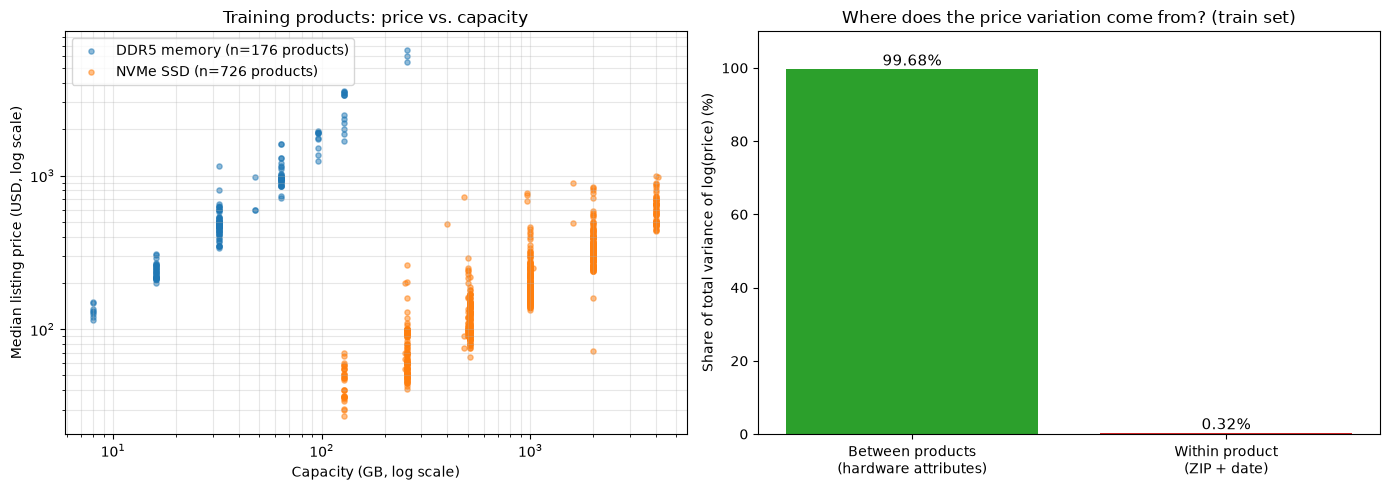

Total variance of log(price): 0.7125
Between-product share: 99.68% | Within-product (ZIP + date) share: 0.32%
Typical within-product deviation (std): 0.0477 log units ~ 4.9% of price


In [5]:
SERIES_COLORS = {"ddr5_memory": "tab:blue", "nvme_ssd": "tab:orange"}
SERIES_LABELS = {"ddr5_memory": "DDR5 memory", "nvme_ssd": "NVMe SSD"}

prod_train = df_train.groupby(GROUP_COL).agg(
    series_id=("series_id", "first"),
    capacity_gb=("capacity_gb", "first"),
    median_price=("price_amount", "median"),
)

# Variance decomposition of log_price into between- and within-product parts
total_var = df_train[TARGET_COL].var()
within_dev = df_train[TARGET_COL] - df_train.groupby(GROUP_COL)[TARGET_COL].transform("mean")
within_share = within_dev.var() / total_var
between_share = 1 - within_share

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
for s, grp in prod_train.groupby("series_id"):
    ax.scatter(grp["capacity_gb"], grp["median_price"], s=14, alpha=0.5,
               color=SERIES_COLORS[s], label=f"{SERIES_LABELS[s]} (n={len(grp)} products)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Capacity (GB, log scale)")
ax.set_ylabel("Median listing price (USD, log scale)")
ax.set_title("Training products: price vs. capacity")
ax.legend(); ax.grid(alpha=0.3, which="both")

ax = axes[1]
bars = ax.bar(["Between products\n(hardware attributes)", "Within product\n(ZIP + date)"],
              [between_share * 100, within_share * 100], color=["tab:green", "tab:red"])
for b, v in zip(bars, [between_share, within_share]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 1, f"{v*100:.2f}%", ha="center", fontsize=11)
ax.set_ylim(0, 110)
ax.set_ylabel("Share of total variance of log(price) (%)")
ax.set_title("Where does the price variation come from? (train set)")
plt.tight_layout()
plt.show()

print(f"Total variance of log(price): {total_var:.4f}")
print(f"Between-product share: {between_share*100:.2f}% | Within-product (ZIP + date) share: {within_share*100:.2f}%")
print(f"Typical within-product deviation (std): {within_dev.std():.4f} log units ~ {np.expm1(within_dev.std())*100:.1f}% of price")

---

## 5. Baseline, Models and Evaluation Metrics

### 5.1. Baseline: median price by (category, capacity)
A pricing analyst without a model would look up "what does a 2 TB NVMe / a 32 GB DDR5 usually cost?". The baseline does exactly that: it predicts the **training median of `log_price` for the same `(series_id, capacity_gb)` cell**, falling back to the category median when a capacity was never seen in training. It is implemented as a small scikit-learn estimator so it is cross-validated with exactly the same `GroupKFold` folds as the real models.

### 5.2. Two models (all preprocessing inside a `Pipeline`)
| Model | Why | Preprocessing (fitted on training folds only) |
| :--- | :--- | :--- |
| **Ridge regression** | Interpretable linear benchmark on log scale: coefficients ≈ % price premiums. Regularization handles the many one-hot brand columns. | Numeric: median imputation **+ missing indicators** (structural NaN such as `speed_mhz` for NVMe become explicit flags) → standardization. Categorical: one-hot, rare levels (< 5 rows) and unseen test levels grouped as *infrequent*. |
| **HistGradientBoostingRegressor** | Captures non-linear effects and interactions (e.g. PCIe Gen5 premium only for NVMe, RGB premium only for DDR5) without manual feature crosses; handles NaN natively. | Numeric: passthrough (NaN handled by the trees). Categorical: same one-hot encoder. `early_stopping=False` because its internal random validation split would mix rows of the same product (entity leakage). |

Hyperparameters are tuned with `GridSearchCV` + 5-fold `GroupKFold` **on the training set only**; the test set is used **exactly once** in Section 6.

### 5.3. Metrics
* **MAE on log scale** (primary tuning metric): robust to the right-skewed price distribution; an MAE of 0.10 means a typical multiplicative error of about ±10%.
* **RMSE on log scale (≈ RMSLE):** penalizes large misses more.
* **MdAPE (median absolute percentage error in USD):** the answer to the research question in business terms, computed as $\text{median}\,|\hat{p}-p|/p$ with $\hat{p}=\exp(\widehat{\log p})$. Back-transforming a log prediction gives a *median* price estimate, which matches a median-based error metric.
* **Product-level MdAPE:** rows are repeated snapshots, so products with many snapshots dominate row-level metrics. We therefore also report the median over test **products** of each product's median APE (each unseen product counts once).

In [6]:
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.metrics import make_scorer, mean_absolute_error, root_mean_squared_error


class CategoryCapacityMedianBaseline(BaseEstimator, RegressorMixin):
    # Predict the training median log price of the same (series_id, capacity_gb) cell.
    def fit(self, X, y):
        d = X[["series_id", "capacity_gb"]].assign(y=np.asarray(y))
        self.cell_median_ = d.groupby(["series_id", "capacity_gb"])["y"].median()
        self.series_median_ = d.groupby("series_id")["y"].median()
        self.global_median_ = float(np.median(y))
        return self

    def predict(self, X):
        idx = pd.MultiIndex.from_frame(X[["series_id", "capacity_gb"]])
        pred = pd.Series(self.cell_median_.reindex(idx).to_numpy(), index=X.index)
        pred = pred.fillna(X["series_id"].map(self.series_median_)).fillna(self.global_median_)
        return pred.to_numpy(dtype=float)


def mdape(y_log_true, y_log_pred):
    # |exp(p) - exp(t)| / exp(t) = |exp(p - t) - 1|
    return float(np.median(np.abs(np.expm1(np.asarray(y_log_pred) - np.asarray(y_log_true)))))


SCORING = {
    "mae_log": "neg_mean_absolute_error",
    "rmse_log": "neg_root_mean_squared_error",
    "mdape": make_scorer(mdape, greater_is_better=False),
}


def make_ridge(numeric, categorical):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), numeric),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5), categorical),
    ], remainder="drop")
    return Pipeline([("pre", pre), ("model", Ridge())])


def make_hgb(numeric, categorical):
    pre = ColumnTransformer([
        ("num", "passthrough", numeric),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False), categorical),
    ], remainder="drop")
    model = HistGradientBoostingRegressor(max_iter=300, early_stopping=False, random_state=RANDOM_STATE)
    return Pipeline([("pre", pre), ("model", model)])


# One design matrix for all models: pipelines select their own columns, the baseline uses capacity_gb
MODEL_COLS = FEATURES_CORE + ["capacity_gb"]
X_train, y_train, g_train = df_train[MODEL_COLS], df_train[TARGET_COL], df_train[GROUP_COL]
X_test, y_test, g_test = df_test[MODEL_COLS], df_test[TARGET_COL], df_test[GROUP_COL]
print("Model input columns:", FEATURES_CORE)

Model input columns: ['log_capacity_gb', 'log_cap_x_ddr5', 'kit_modules', 'speed_mhz', 'cas_latency', 'pcie_gen', 'series_id', 'brand_clean', 'form_factor', 'has_rgb']


### 5.4. Cross-validated tuning and model comparison (training set only)

The grids are deliberately small: there are only ~900 distinct training products, so the effective sample size is much smaller than the ~100k rows. `min_samples_leaf` is the key regularizer for the trees: because each product appears up to ~480 times, small leaves can memorize individual products instead of learning attribute effects.

In [7]:
import time

# Baseline (no hyperparameters)
t0 = time.time()
cv_base = cross_validate(CategoryCapacityMedianBaseline(), X_train, y_train, groups=g_train,
                         cv=gkf, scoring=SCORING, n_jobs=1)

# Ridge
ridge_search = GridSearchCV(
    make_ridge(NUMERIC_CORE, CATEGORICAL_CORE),
    param_grid={"model__alpha": [1, 10, 100, 1000, 10000]},
    cv=gkf, scoring=SCORING, refit="mae_log", n_jobs=1,
)
ridge_search.fit(X_train, y_train, groups=g_train)

# HistGradientBoosting (uses native OpenMP multithreading in-process when n_jobs=1)
hgb_search = GridSearchCV(
    make_hgb(NUMERIC_CORE, CATEGORICAL_CORE),
    param_grid={
        "model__learning_rate": [0.05],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__min_samples_leaf": [20, 50, 300],
    },
    cv=gkf, scoring=SCORING, refit="mae_log", n_jobs=1,
)
hgb_search.fit(X_train, y_train, groups=g_train)
print(f"CV finished in {time.time() - t0:.0f} s")
print("Best Ridge params:", ridge_search.best_params_)
print("Best HGB params  :", hgb_search.best_params_)


def cv_row(name, res, idx=None):
    get = (lambda k: -res[f"test_{k}"]) if idx is None else (lambda k: -np.array(
        [res[f"split{i}_test_{k}"][idx] for i in range(gkf.n_splits)]))
    return {
        "model": name,
        "CV MAE (log)": f"{get('mae_log').mean():.4f} ± {get('mae_log').std():.4f}",
        "CV RMSE (log)": f"{get('rmse_log').mean():.4f} ± {get('rmse_log').std():.4f}",
        "CV MdAPE (%)": f"{get('mdape').mean()*100:.2f} ± {get('mdape').std()*100:.2f}",
    }


cv_table = pd.DataFrame([
    cv_row("Baseline: median by (series, capacity)", cv_base),
    cv_row(f"Ridge {ridge_search.best_params_}", ridge_search.cv_results_, ridge_search.best_index_),
    cv_row(f"HGB {hgb_search.best_params_}", hgb_search.cv_results_, hgb_search.best_index_),
])
print("\n=== 5-FOLD GROUPKFOLD RESULTS ON TRAINING PRODUCTS (mean ± std over folds) ===")
display(cv_table)

# Full HGB grid for transparency
grid_view = pd.DataFrame(hgb_search.cv_results_)[["params", "mean_test_mae_log", "std_test_mae_log", "mean_test_mdape"]]
grid_view[["mean_test_mae_log", "mean_test_mdape"]] *= -1
grid_view["mean_test_mdape"] *= 100
display(grid_view.sort_values("mean_test_mae_log").round(4).rename(columns={"mean_test_mdape": "mean_test_mdape_%"}))

CV finished in 251 s
Best Ridge params: {'model__alpha': 1000}
Best HGB params  : {'model__learning_rate': 0.05, 'model__max_leaf_nodes': 31, 'model__min_samples_leaf': 50}

=== 5-FOLD GROUPKFOLD RESULTS ON TRAINING PRODUCTS (mean ± std over folds) ===


,model,CV MAE (log),CV RMSE (log),CV MdAPE (%)
0,"Baseline: median by (series, capacity)",0.1936 ± 0.0251,0.2691 ± 0.0238,15.23 ± 2.96
1,Ridge {'model__alpha': 1000},0.1595 ± 0.0336,0.2286 ± 0.0543,11.29 ± 1.41
2,"HGB {'model__learning_rate': 0.05, 'model__max...",0.1481 ± 0.0238,0.2179 ± 0.0377,9.04 ± 1.35


,params,mean_test_mae_log,std_test_mae_log,mean_test_mdape_%
4,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1481,0.0238,9.0359
6,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1489,0.0264,9.7335
3,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1491,0.0267,9.5701
1,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1542,0.0196,9.3296
0,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1545,0.0212,9.7394
7,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1563,0.0277,9.9768
5,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1578,0.0311,10.0525
2,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1589,0.0272,10.9270
8,"{'model__learning_rate': 0.05, 'model__max_lea...",0.1612,0.0323,9.9047


---

## 6. Final Evaluation on the Hold-out Test Set (used exactly once)

All three models are refit on the full training set (the searches already did this with `refit="mae_log"`) and evaluated once on the 226 unseen test products. To quantify uncertainty, a **product-level bootstrap** (1,000 resamples of test *products*, not rows, because rows of the same product are not independent) gives 95% confidence intervals for MdAPE and for the relative improvement over the baseline.

In [8]:
baseline_model = CategoryCapacityMedianBaseline().fit(X_train, y_train)
final_models = {
    "Baseline": baseline_model,
    "Ridge": ridge_search.best_estimator_,
    "HistGradientBoosting": hgb_search.best_estimator_,
}
test_pred = {name: m.predict(X_test) for name, m in final_models.items()}


def product_level_mdape(y_true, y_pred, groups):
    ape = pd.Series(np.abs(np.expm1(y_pred - np.asarray(y_true))), index=groups.index)
    return float(ape.groupby(groups).median().median())


rows = []
for name, pred in test_pred.items():
    rows.append({
        "model": name,
        "MAE (log)": mean_absolute_error(y_test, pred),
        "RMSE (log)": root_mean_squared_error(y_test, pred),
        "MdAPE rows (%)": mdape(y_test, pred) * 100,
        "MdAPE products (%)": product_level_mdape(y_test, pred, g_test) * 100,
        "Share within ±10% (%)": np.mean(np.abs(np.expm1(pred - y_test)) <= 0.10) * 100,
    })
test_table = pd.DataFrame(rows).set_index("model")
base_mdape = test_table.loc["Baseline", "MdAPE rows (%)"]
test_table["MdAPE reduction vs baseline (%)"] = (1 - test_table["MdAPE rows (%)"] / base_mdape) * 100

# ---- Product-level bootstrap CI
rng = np.random.default_rng(RANDOM_STATE)
prod_codes, prod_uniques = pd.factorize(g_test)
rows_by_prod = [np.flatnonzero(prod_codes == k) for k in range(len(prod_uniques))]
ape_by_model = {n: np.abs(np.expm1(p - y_test.to_numpy())) for n, p in test_pred.items()}
N_BOOT = 1000
boot = {n: np.empty(N_BOOT) for n in test_pred}
for b in range(N_BOOT):
    idx = np.concatenate([rows_by_prod[k] for k in rng.integers(0, len(rows_by_prod), len(rows_by_prod))])
    for n in test_pred:
        boot[n][b] = np.median(ape_by_model[n][idx])
for n in test_pred:
    lo, hi = np.percentile(boot[n] * 100, [2.5, 97.5])
    test_table.loc[n, "MdAPE 95% CI"] = f"[{lo:.1f}, {hi:.1f}]"
rel_impr = (1 - boot["HistGradientBoosting"] / boot["Baseline"]) * 100
impr_lo, impr_hi = np.percentile(rel_impr, [2.5, 97.5])

print("=== HOLD-OUT TEST SET (226 unseen products, 23,483 rows) ===")
display(test_table.round(3))
print(f"HGB relative MdAPE reduction vs baseline: {test_table.loc['HistGradientBoosting', 'MdAPE reduction vs baseline (%)']:.1f}% "
      f"(95% product-bootstrap CI [{impr_lo:.1f}%, {impr_hi:.1f}%])")

=== HOLD-OUT TEST SET (226 unseen products, 23,483 rows) ===


,MAE (log),RMSE (log),MdAPE rows (%),MdAPE products (%),Share within ±10% (%),MdAPE reduction vs baseline (%),MdAPE 95% CI
model,,,,,,,
Baseline,0.219,0.290,18.695,17.601,30.081,0.000,"[14.5, 22.8]"
Ridge,0.149,0.200,10.719,10.685,45.092,42.665,"[9.3, 14.7]"
HistGradientBoosting,0.118,0.172,8.806,7.426,57.970,52.895,"[6.6, 10.0]"


HGB relative MdAPE reduction vs baseline: 52.9% (95% product-bootstrap CI [39.1%, 66.9%])


**Charts.** Left: test MdAPE of each model with 95% product-bootstrap intervals. Right: predicted vs. actual price for each unseen test product (median over its snapshots) for the best model; the dashed band marks ±25%.

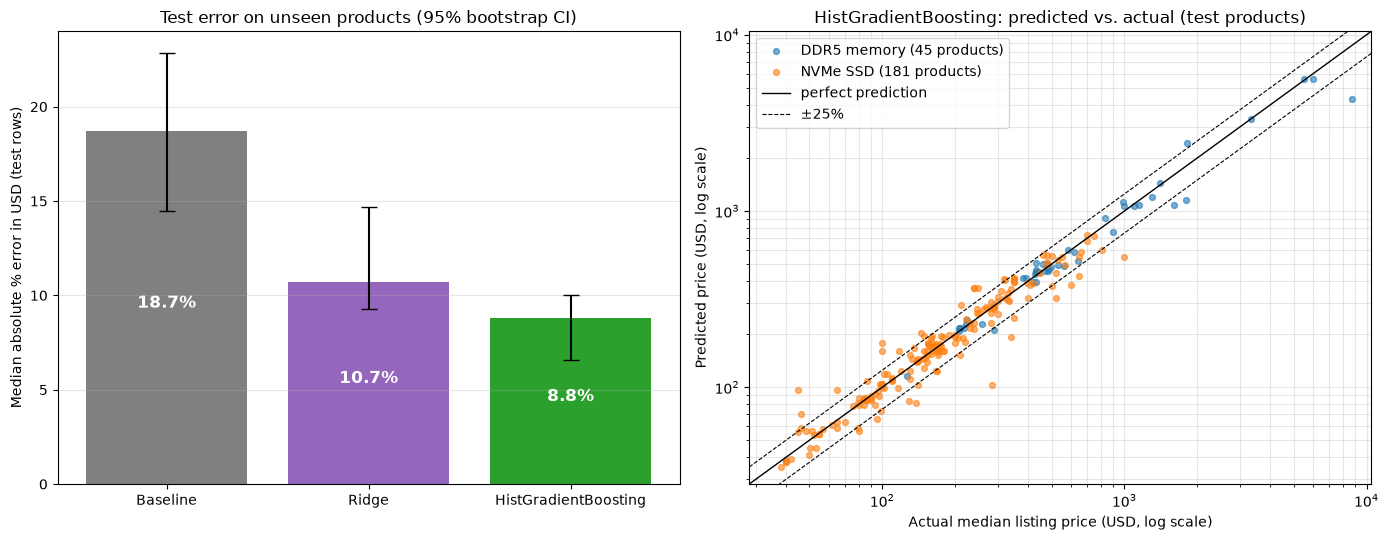

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

ax = axes[0]
names = list(test_pred)
vals = [test_table.loc[n, "MdAPE rows (%)"] for n in names]
err_lo = [vals[i] - np.percentile(boot[n] * 100, 2.5) for i, n in enumerate(names)]
err_hi = [np.percentile(boot[n] * 100, 97.5) - vals[i] for i, n in enumerate(names)]
bars = ax.bar(names, vals, yerr=[err_lo, err_hi], capsize=6, color=["grey", "tab:purple", "tab:green"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v / 2, f"{v:.1f}%", ha="center", color="white", fontsize=12, weight="bold")
ax.set_ylabel("Median absolute % error in USD (test rows)")
ax.set_title("Test error on unseen products (95% bootstrap CI)")
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
prod_eval = pd.DataFrame({
    "product": g_test, "series_id": df_test["series_id"],
    "actual": df_test["price_amount"], "pred": np.exp(test_pred["HistGradientBoosting"]),
}).groupby("product").agg(series_id=("series_id", "first"), actual=("actual", "median"), pred=("pred", "median"))
for s, grp in prod_eval.groupby("series_id"):
    ax.scatter(grp["actual"], grp["pred"], s=18, alpha=0.6, color=SERIES_COLORS[s],
               label=f"{SERIES_LABELS[s]} ({len(grp)} products)")
lims = np.array([prod_eval[["actual", "pred"]].min().min() * 0.8, prod_eval[["actual", "pred"]].max().max() * 1.2])
ax.plot(lims, lims, "k-", lw=1, label="perfect prediction")
ax.plot(lims, lims * 1.25, "k--", lw=0.8, label="±25%")
ax.plot(lims, lims * 0.75, "k--", lw=0.8)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Actual median listing price (USD, log scale)")
ax.set_ylabel("Predicted price (USD, log scale)")
ax.set_title("HistGradientBoosting: predicted vs. actual (test products)")
ax.legend(); ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

---

## 7. Error Analysis (best model on the test set)

Where does the model fail? Errors are broken down by category, capacity tier and brand, and the worst-predicted products are listed. `median signed error` shows bias (positive = model over-prices).

In [10]:
err = df_test[[GROUP_COL, "series_id", "brand_clean", "capacity_gb", "form_factor", "price_amount"]].copy()
err["pred_usd"] = np.exp(test_pred["HistGradientBoosting"])
err["base_usd"] = np.exp(test_pred["Baseline"])
err["ape"] = (err["pred_usd"] - err["price_amount"]).abs() / err["price_amount"]
err["ape_base"] = (err["base_usd"] - err["price_amount"]).abs() / err["price_amount"]
err["signed"] = err["pred_usd"] / err["price_amount"] - 1


def summarize(by):
    out = err.groupby(by).agg(
        rows=("ape", "size"),
        products=(GROUP_COL, "nunique"),
        MdAPE_model_pct=("ape", lambda s: s.median() * 100),
        MdAPE_baseline_pct=("ape_base", lambda s: s.median() * 100),
        median_signed_error_pct=("signed", lambda s: s.median() * 100),
    )
    return out.round(1)


print("=== By category ===")
display(summarize("series_id"))

err["capacity_tier"] = err["series_id"].map({"ddr5_memory": "DDR5", "nvme_ssd": "NVMe"}) + " " + \
    np.where(err["capacity_gb"] >= 1000, (err["capacity_gb"] / 1000).map("{:g} TB".format),
             err["capacity_gb"].map("{:g} GB".format))
print("=== By capacity tier (tiers with >= 3 test products) ===")
cap_tbl = summarize("capacity_tier")
display(cap_tbl[cap_tbl["products"] >= 3])

print("=== By brand (10 brands with most test products) ===")
brand_tbl = summarize("brand_clean")
display(brand_tbl.sort_values("products", ascending=False).head(10))

print("=== 10 worst-predicted test products (product-level median APE) ===")
worst = err.groupby(GROUP_COL).agg(
    series_id=("series_id", "first"), brand=("brand_clean", "first"), capacity_gb=("capacity_gb", "first"),
    actual_usd=("price_amount", "median"), pred_usd=("pred_usd", "median"), ape=("ape", "median"),
).sort_values("ape", ascending=False).head(10)
worst["product_name"] = worst.index.str.slice(0, 80)
display(worst.reset_index(drop=True)[["product_name", "series_id", "brand", "capacity_gb", "actual_usd", "pred_usd", "ape"]].round(2))

=== By category ===


,rows,products,MdAPE_model_pct,MdAPE_baseline_pct,median_signed_error_pct
series_id,,,,,
ddr5_memory,2739,45,4.9,9.3,3.0
nvme_ssd,20744,181,8.9,20.2,2.2


=== By capacity tier (tiers with >= 3 test products) ===


,rows,products,MdAPE_model_pct,MdAPE_baseline_pct,median_signed_error_pct
capacity_tier,,,,,
DDR5 16 GB,324,8,2.0,4.6,1.9
DDR5 256 GB,165,3,6.1,8.0,-6.1
DDR5 32 GB,1312,22,4.2,7.8,3.0
DDR5 64 GB,470,8,8.0,17.4,-6.1
NVMe 1 TB,6213,46,6.8,20.1,1.1
NVMe 128 GB,737,10,5.5,9.1,-5.5
NVMe 2 TB,4048,37,12.8,18.0,8.8
NVMe 256 GB,2685,22,9.7,23.1,-1.2
NVMe 4 TB,2001,15,8.5,19.7,0.3


=== By brand (10 brands with most test products) ===


,rows,products,MdAPE_model_pct,MdAPE_baseline_pct,median_signed_error_pct
brand_clean,,,,,
GENERIC,1411,25,10.4,21.4,3.8
G.SKILL,703,15,6.3,8.3,-5.5
FIKWOT,1323,12,5.5,18.7,-5.5
WESTERN DIGITAL,1736,12,14.1,23.7,13.9
CRUCIAL,1257,10,18.9,18.7,18.9
PATRIOT,843,9,9.0,9.6,1.9
DELL,1773,8,7.8,34.2,-0.9
KINGSPEC,1051,8,8.8,30.1,8.8
KINGSTON,622,7,23.6,24.1,-7.6


=== 10 worst-predicted test products (product-level median APE) ===


,product_name,series_id,brand,capacity_gb,actual_usd,pred_usd,ape
0,512GB NM620 M.2 2280 NVMe PCIe Gen3x4 Internal...,nvme_ssd,GENERIC,512.0,45.02,95.80,1.13
1,Western Digital 500GB WD Green SN350 NVMe Inte...,nvme_ssd,WESTERN DIGITAL,500.0,99.99,177.39,0.77
2,SK hynix Platinum P41 500GB SSD PCIe NVMe Gen4...,nvme_ssd,SK,500.0,285.00,103.23,0.64
3,Western Digital 500GB WD Green SN3000 NVMe Int...,nvme_ssd,WESTERN DIGITAL,500.0,99.99,160.46,0.60
4,256GB M.2 PCIe Gen4 x4 NVMe SSD AM6A0 RPETJ256...,nvme_ssd,GENERIC,256.0,45.99,70.70,0.54
5,WD Green SN350 2TB NVMe SSD Internal Solid Sta...,nvme_ssd,WESTERN DIGITAL,2000.0,239.99,367.88,0.53
6,"WD Green SN350 2TB NVMe SSD, M.2 2280 PCIe Gen...",nvme_ssd,WESTERN DIGITAL,2000.0,239.99,367.88,0.53
7,V-Color DDR5 256GB (64GBx4) 6400MHz CL60 ECC R...,ddr5_memory,V-COLOR,256.0,8719.99,4316.40,0.50
8,OEM Samsung 256GB M.2 PCI-e NVME SSD Internal ...,nvme_ssd,OEM,256.0,64.99,96.10,0.48
9,Western Digital 2TB WD Green SN350 NVMe Intern...,nvme_ssd,WESTERN DIGITAL,2000.0,249.00,367.88,0.48


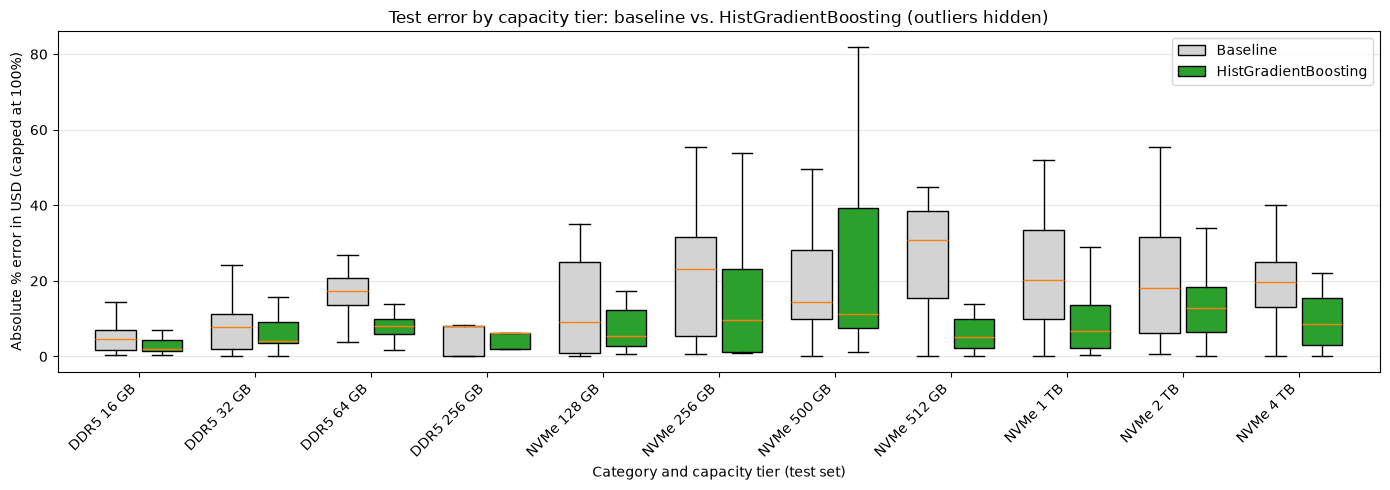

In [11]:
tiers = cap_tbl[cap_tbl["products"] >= 3].index
order = sorted(tiers, key=lambda t: (t.split()[0], err.loc[err["capacity_tier"] == t, "capacity_gb"].iloc[0]))
data_model = [err.loc[err["capacity_tier"] == t, "ape"].clip(upper=1.0) * 100 for t in order]
data_base = [err.loc[err["capacity_tier"] == t, "ape_base"].clip(upper=1.0) * 100 for t in order]

fig, ax = plt.subplots(figsize=(14, 5))
pos = np.arange(len(order))
b1 = ax.boxplot(data_base, positions=pos - 0.2, widths=0.35, patch_artist=True, showfliers=False)
b2 = ax.boxplot(data_model, positions=pos + 0.2, widths=0.35, patch_artist=True, showfliers=False)
for p in b1["boxes"]: p.set_facecolor("lightgrey")
for p in b2["boxes"]: p.set_facecolor("tab:green")
ax.set_xticks(pos); ax.set_xticklabels(order, rotation=45, ha="right")
ax.set_ylabel("Absolute % error in USD (capped at 100%)")
ax.set_xlabel("Category and capacity tier (test set)")
ax.set_title("Test error by capacity tier: baseline vs. HistGradientBoosting (outliers hidden)")
ax.legend([b1["boxes"][0], b2["boxes"][0]], ["Baseline", "HistGradientBoosting"])
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

---

## 8. Which Attributes Drive Price? (Permutation Importance on the Test Set)

**Method.** For each attribute we randomly shuffle its column(s) in the test set, re-predict with the fitted HGB pipeline and measure how much the test MAE (log) increases; repeated 10 times. A large increase means the model relies on that attribute for unseen products. We permute **attribute groups** rather than single columns: `capacity_gb`, `log_capacity_gb` and `log_cap_x_ddr5` all encode capacity, so permuting one while the others remain intact would understate the importance of capacity.

**Caveat.** Permutation importance measures reliance *of this model*, not causality. Correlated attributes share credit: for example `series_id` is almost fully implied by `form_factor` (UDIMM/SODIMM vs M.2) and by which spec columns are missing, so its own importance is understated.

Unpermuted test MAE (log) = 0.1182, MdAPE = 8.81%


,attribute,MAE_increase_mean,MAE_increase_std,MdAPE_increase_pp,share_of_total_%
0,capacity,0.7500,0.0028,55.2233,82.9969
1,brand,0.0793,0.0006,6.6536,8.7806
2,form_factor,0.0385,0.0003,2.7254,4.2585
3,pcie_gen,0.0265,0.0004,1.5717,2.9326
4,cas_latency,0.0056,0.0001,0.1556,0.6250
5,speed_mhz,0.0032,0.0001,0.0191,0.3556
6,kit_modules (number of sticks),0.0003,0.0001,0.0000,0.0383
7,has_rgb,0.0001,0.0000,-0.0070,0.0125
8,series_id (DDR5 vs NVMe),0.0000,0.0000,0.0000,0.0000


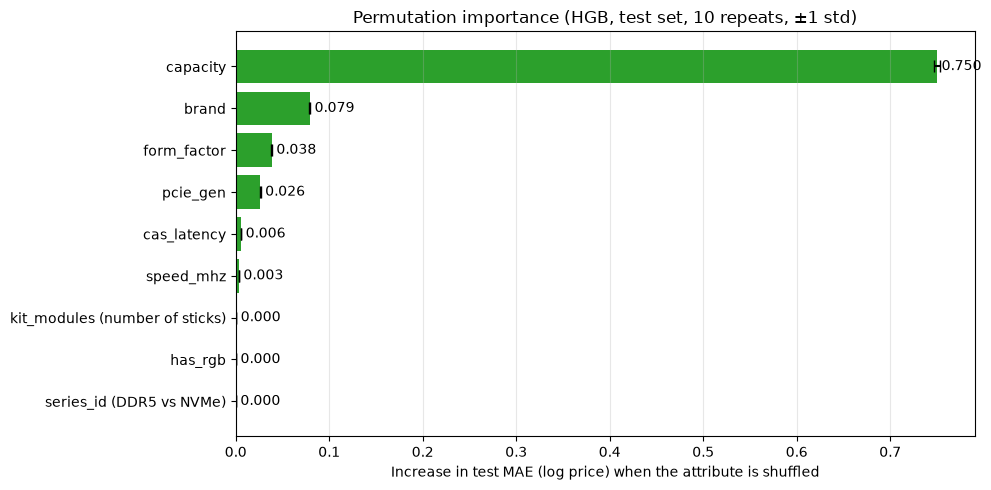

In [12]:
FEATURE_GROUPS = {
    "capacity": ["capacity_gb", "log_capacity_gb", "log_cap_x_ddr5"],
    "series_id (DDR5 vs NVMe)": ["series_id"],
    "brand": ["brand_clean"],
    "form_factor": ["form_factor"],
    "kit_modules (number of sticks)": ["kit_modules"],
    "speed_mhz": ["speed_mhz"],
    "cas_latency": ["cas_latency"],
    "pcie_gen": ["pcie_gen"],
    "has_rgb": ["has_rgb"],
}
best_model = final_models["HistGradientBoosting"]
base_mae = mean_absolute_error(y_test, best_model.predict(X_test))
base_md = mdape(y_test, best_model.predict(X_test))
N_REPEATS = 10
rng = np.random.default_rng(RANDOM_STATE)
imp_rows = []
for gname, cols in FEATURE_GROUPS.items():
    d_mae, d_md = [], []
    for _ in range(N_REPEATS):
        Xp = X_test.copy()
        perm = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].to_numpy()[perm]          # shuffle the whole group jointly
        p = best_model.predict(Xp)
        d_mae.append(mean_absolute_error(y_test, p) - base_mae)
        d_md.append(mdape(y_test, p) - base_md)
    imp_rows.append({"attribute": gname, "MAE_increase_mean": np.mean(d_mae), "MAE_increase_std": np.std(d_mae),
                     "MdAPE_increase_pp": np.mean(d_md) * 100})
imp = pd.DataFrame(imp_rows).sort_values("MAE_increase_mean", ascending=False).reset_index(drop=True)
imp["share_of_total_%"] = imp["MAE_increase_mean"].clip(lower=0) / imp["MAE_increase_mean"].clip(lower=0).sum() * 100
print(f"Unpermuted test MAE (log) = {base_mae:.4f}, MdAPE = {base_md*100:.2f}%")
display(imp.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(imp["attribute"][::-1], imp["MAE_increase_mean"][::-1], xerr=imp["MAE_increase_std"][::-1],
        color="tab:green", capsize=4)
for y_pos, v in enumerate(imp["MAE_increase_mean"][::-1]):
    ax.text(v + 0.005, y_pos, f"{v:.3f}", va="center")
ax.set_xlabel("Increase in test MAE (log price) when the attribute is shuffled")
ax.set_title("Permutation importance (HGB, test set, 10 repeats, ±1 std)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Cross-check with the linear model.** Ridge coefficients on the log scale translate into approximate % price premiums ($e^{\beta}-1$), holding the other attributes fixed. Numeric features are standardized, so their coefficients are per one standard deviation. This is a sanity check on the direction of effects, not a causal estimate.

In [13]:
ridge_best = final_models["Ridge"]
feat_names = ridge_best.named_steps["pre"].get_feature_names_out()
coefs = pd.Series(ridge_best.named_steps["model"].coef_, index=feat_names)
coef_tbl = pd.DataFrame({"coef_log": coefs, "approx_premium_%": np.expm1(coefs) * 100})
print("=== 12 largest positive and negative Ridge effects ===")
display(pd.concat([coef_tbl.sort_values("coef_log", ascending=False).head(12),
                   coef_tbl.sort_values("coef_log").head(12)]).round(3))

=== 12 largest positive and negative Ridge effects ===


,coef_log,approx_premium_%
num__log_capacity_gb,0.991,169.489
num__log_cap_x_ddr5,0.398,48.816
cat__brand_clean_SAMSUNG,0.254,28.970
cat__brand_clean_WESTERN DIGITAL,0.178,19.424
cat__brand_clean_KINGSTON,0.141,15.142
cat__brand_clean_G.SKILL,0.139,14.916
cat__series_id_ddr5_memory,0.138,14.831
cat__brand_clean_SEAGATE,0.135,14.470
cat__brand_clean_LEXAR,0.120,12.753
cat__brand_clean_SANDISK,0.113,11.976


---

## 9. Do ZIP (`geography_id`) and Date (`observed_date`) Add Information?

Three complementary checks:
1. **Upper bound (Section 4):** ZIP and date can only explain the *within-product* variance.
2. **Ablation with cross-validation:** the tuned HGB is re-trained on the training folds with (a) core attributes, (b) + ZIP (one-hot `geography_id`), (c) + date (`day_index`), (d) + both, using the same `GroupKFold` folds. Paired fold-by-fold differences show whether the change is larger than fold-to-fold noise. The test set is **not** reused for this.
3. **Effect size within products:** for each ZIP and each day, the average deviation of a product's price from that product's own mean price (training set). This shows how large a ZIP/day effect actually is in dollars-and-cents terms.

In [14]:
best_hgb_params = hgb_search.best_params_
ablation_sets = {
    "Core attributes": (NUMERIC_CORE, CATEGORICAL_CORE),
    "Core + ZIP": (NUMERIC_CORE, CATEGORICAL_CORE + ["geography_id"]),
    "Core + date": (NUMERIC_CORE + ["day_index"], CATEGORICAL_CORE),
    "Core + ZIP + date": (NUMERIC_CORE + ["day_index"], CATEGORICAL_CORE + ["geography_id"]),
}
X_train_ctx = df_train[MODEL_COLS + ["geography_id", "day_index"]]
abl_res = {}
for name, (num, cat) in ablation_sets.items():
    pipe = make_hgb(num, cat).set_params(**best_hgb_params)
    abl_res[name] = cross_validate(pipe, X_train_ctx, y_train, groups=g_train, cv=gkf, scoring=SCORING, n_jobs=1)

core_mae = -abl_res["Core attributes"]["test_mae_log"]
core_md = -abl_res["Core attributes"]["test_mdape"]
abl_rows = []
for name, res in abl_res.items():
    mae = -res["test_mae_log"]; md_ = -res["test_mdape"]
    diff = mae - core_mae
    abl_rows.append({
        "feature set": name,
        "CV MAE (log)": mae.mean(),
        "CV MdAPE (%)": md_.mean() * 100,
        "Δ MAE vs core (mean)": diff.mean(),
        "Δ MAE vs core (min..max over folds)": f"{diff.min():+.4f} .. {diff.max():+.4f}",
        "Δ MdAPE vs core (pp)": (md_ - core_md).mean() * 100,
        "fold-to-fold std of core MAE": core_mae.std(),
    })
abl_table = pd.DataFrame(abl_rows)
print("=== ABLATION: 5-fold GroupKFold on training products (same folds, same HGB hyperparameters) ===")
display(abl_table.round(4))

=== ABLATION: 5-fold GroupKFold on training products (same folds, same HGB hyperparameters) ===


,feature set,CV MAE (log),CV MdAPE (%),Δ MAE vs core (mean),Δ MAE vs core (min..max over folds),Δ MdAPE vs core (pp),fold-to-fold std of core MAE
0,Core attributes,0.1481,9.0359,0.0000,+0.0000 .. +0.0000,0.0000,0.0238
1,Core + ZIP,0.1479,9.1851,-0.0002,-0.0010 .. +0.0017,0.1492,0.0238
2,Core + date,0.1478,9.1866,-0.0003,-0.0013 .. +0.0012,0.1507,0.0238
3,Core + ZIP + date,0.1477,9.0628,-0.0004,-0.0024 .. +0.0023,0.0268,0.0238


ZIP + day dummies explain 0.4% of the within-product variance, i.e. 0.001% of the TOTAL variance of log(price).
Range of average ZIP effects: -0.08% .. +0.07%
Range of average daily effects: -0.49% .. +0.69%


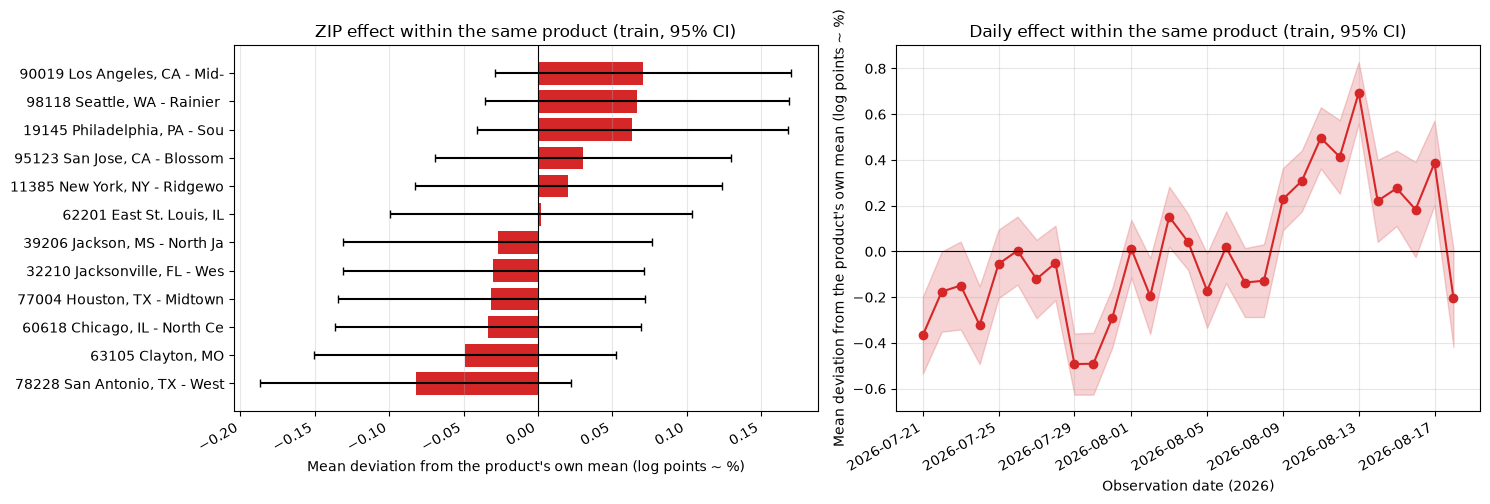

In [15]:
# Within-product deviations (training set): how far is a listing from its own product's mean price?
wp = df_train[[GROUP_COL, "geography_id", "geography_label", "observed_date_dt", "day_index"]].copy()
wp["dev_pct"] = within_dev * 100   # log points ~ % (symmetric, avoids the upward bias of exp-1 averages)

zip_eff = wp.groupby(["geography_id", "geography_label"])["dev_pct"].agg(["mean", "sem", "size"]).reset_index()
zip_eff["label"] = zip_eff["geography_id"] + " " + zip_eff["geography_label"].str.slice(0, 22)
zip_eff = zip_eff.sort_values("mean")
day_eff = wp.groupby("observed_date_dt")["dev_pct"].agg(["mean", "sem"]).reset_index()

# Share of TOTAL variance explained by ZIP + day dummies on the within-product deviations
from sklearn.linear_model import LinearRegression
D = pd.get_dummies(wp[["geography_id"]].assign(day=wp["day_index"].astype(str)), drop_first=True)
r2_within = LinearRegression().fit(D, within_dev).score(D, within_dev)
print(f"ZIP + day dummies explain {r2_within*100:.1f}% of the within-product variance, "
      f"i.e. {r2_within*within_share*100:.3f}% of the TOTAL variance of log(price).")
print(f"Range of average ZIP effects: {zip_eff['mean'].min():+.2f}% .. {zip_eff['mean'].max():+.2f}%")
print(f"Range of average daily effects: {day_eff['mean'].min():+.2f}% .. {day_eff['mean'].max():+.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
ax.barh(zip_eff["label"], zip_eff["mean"], xerr=1.96 * zip_eff["sem"], color="tab:red", capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Mean deviation from the product's own mean (log points ~ %)")
ax.set_title("ZIP effect within the same product (train, 95% CI)")
ax.grid(axis="x", alpha=0.3)

ax = axes[1]
ax.plot(day_eff["observed_date_dt"], day_eff["mean"], marker="o", color="tab:red")
ax.fill_between(day_eff["observed_date_dt"], day_eff["mean"] - 1.96 * day_eff["sem"],
                day_eff["mean"] + 1.96 * day_eff["sem"], alpha=0.2, color="tab:red")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Observation date (2026)")
ax.set_ylabel("Mean deviation from the product's own mean (log points ~ %)")
ax.set_title("Daily effect within the same product (train, 95% CI)")
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

### 9.1. Temporal stability of the core model

The core model ignores the date. If prices drifted strongly during the 29 days, its error on the test products would trend over time. The chart below shows the daily test MdAPE of the baseline and HGB.

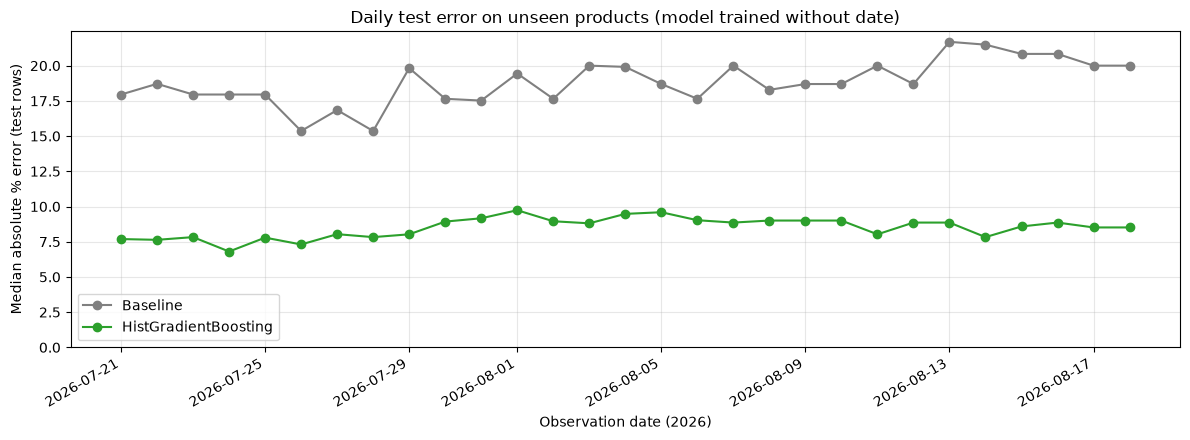

Daily HGB MdAPE ranges from 6.8% to 9.7%


In [16]:
daily = pd.DataFrame({
    "date": df_test["observed_date_dt"],
    "ape_model": np.abs(np.expm1(test_pred["HistGradientBoosting"] - y_test)) * 100,
    "ape_base": np.abs(np.expm1(test_pred["Baseline"] - y_test)) * 100,
}).groupby("date").median()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily["ape_base"], marker="o", color="grey", label="Baseline")
ax.plot(daily.index, daily["ape_model"], marker="o", color="tab:green", label="HistGradientBoosting")
ax.set_ylim(0, None)
ax.set_xlabel("Observation date (2026)")
ax.set_ylabel("Median absolute % error (test rows)")
ax.set_title("Daily test error on unseen products (model trained without date)")
ax.legend(); ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
print(f"Daily HGB MdAPE ranges from {daily['ape_model'].min():.1f}% to {daily['ape_model'].max():.1f}%")

In [17]:
# Key numbers used in the conclusion below (printed so the text can be checked against the run)
hgb_row = test_table.loc["HistGradientBoosting"]
print(f"Baseline test MdAPE       : {test_table.loc['Baseline', 'MdAPE rows (%)']:.1f}%")
print(f"Ridge test MdAPE          : {test_table.loc['Ridge', 'MdAPE rows (%)']:.1f}%")
print(f"HGB test MdAPE            : {hgb_row['MdAPE rows (%)']:.1f}% (products: {hgb_row['MdAPE products (%)']:.1f}%)")
print(f"HGB reduction vs baseline : {hgb_row['MdAPE reduction vs baseline (%)']:.1f}% (95% CI {impr_lo:.1f}..{impr_hi:.1f}%)")
print(f"Top-3 attributes          : {', '.join(imp['attribute'].head(3))}")
print(f"Within-product variance   : {within_share*100:.2f}% of total")
print(f"ZIP+date ablation Δ MdAPE : {abl_table.loc[3, 'Δ MdAPE vs core (pp)']:+.2f} pp")

Baseline test MdAPE       : 18.7%
Ridge test MdAPE          : 10.7%
HGB test MdAPE            : 8.8% (products: 7.4%)
HGB reduction vs baseline : 52.9% (95% CI 39.1..66.9%)
Top-3 attributes          : capacity, brand, form_factor
Within-product variance   : 0.32% of total
ZIP+date ablation Δ MdAPE : +0.03 pp


---

## 10. Final Synthesis, Interpretation & Limitations (Answer to Q6)

### 10.1. How accurately can we predict the listing price of an unseen product compared to the baseline?
* **Baseline Benchmark (`Category × Capacity` Median):** Predicting the training median price for the same `(series_id, capacity_gb)` tier yields a test **MdAPE of 18.70%** across the 23,483 hold-out rows (**17.60%** at the product level across 226 unseen products; log-MAE = `0.219`, log-RMSE = `0.290`). Only **30.1%** of unseen listing snapshots fall within ±10% of the baseline estimate.
* **Linear Benchmark (`Ridge` on log price):** Adding parsed hardware attributes (`brand_clean`, `form_factor`, `kit_modules`, `speed_mhz`, `cas_latency`, `pcie_gen`, `has_rgb`) with L2 regularization (`alpha = 1000`) reduces test **MdAPE to 10.72%** (**10.69%** product-level; a **42.7% relative error reduction** vs. baseline; log-MAE = `0.149`).
* **Best Model (`HistGradientBoostingRegressor`):** Non-linear gradient-boosted trees achieve a test **MdAPE of 8.81%** (95% product-bootstrap CI: **[6.6%, 10.0%]**) and a **product-level MdAPE of 7.43%** (log-MAE = `0.118`, log-RMSE = `0.172`). This represents a **52.9% relative reduction in median percentage error** compared to the category-capacity baseline (95% product-bootstrap CI: **[39.1%, 66.9%]** — or **57.8% reduction** at the product level), nearly doubling the share of predictions within ±10% of the actual listing price from **30.1% to 58.0%**.
* **By Hardware Category:** Prediction is even tighter for **DDR5 memory** (test MdAPE **4.9%** vs. **9.3%** baseline across 45 unseen kits) than for **NVMe SSDs** (test MdAPE **8.9%** vs. **20.2%** baseline across 181 unseen drives), because DDR5 titles expose almost all price-relevant specs (capacity, module count, MHz speed, CL timing), whereas NVMe titles omit key internal tiering specs (NAND flash type, DRAM cache, controller).

### 10.2. Which hardware attributes drive listing prices the most?
Grouped permutation importance on the hold-out test set (measuring the increase in log-MAE when each attribute group is randomly shuffled across 10 repeats) reveals a sharp hierarchy:
1. **Capacity (`capacity_gb` / `log_capacity_gb`):** By far the dominant determinant of price, increasing test log-MAE by **+0.750** (+55.2 percentage points in MdAPE), accounting for **83.0%** of total model reliance. On the log-linear Ridge cross-check, capacity scales nearly proportionally with price, with a steeper slope for DDR5 than NVMe (`log_cap_x_ddr5` interaction = `+0.398`).
2. **Brand (`brand_clean`):** The second most important factor (**+0.079** log-MAE increase; **+6.7 pp** MdAPE; **8.8%** share). Ridge coefficients confirm strong brand tiering holding specs constant: enterprise/flagship brands (*Samsung* `+29.0%`, *Western Digital* `+19.4%`, *Kingston* `+15.1%`, *G.SKILL* `+14.9%`, *Seagate* `+14.5%`) command substantial premiums over white-label `GENERIC` (`-8.5%`), *Fikwot* (`-9.3%`), *Fanxiang* (`-10.1%`), and *OEM* (`-12.8%`) listings.
3. **Form Factor (`form_factor`) & PCIe Generation (`pcie_gen`):** Rank 3rd (**+0.039** log-MAE; **4.3%** share) and 4th (**+0.027** log-MAE; **2.9%** share), separating compact M.2 2230/2242 and PCIe Gen5 drives from mainstream M.2 2280 Gen3/Gen4 drives, as well as UDIMM desktop vs. SODIMM laptop memory.
4. **Fine-grained DDR5 Timings (`cas_latency`, `speed_mhz`, `kit_modules`, `has_rgb`):** Account for the remaining **~1.0%** of overall test importance because they apply only to the DDR5 subset (11.7% of test rows), though within DDR5 they cut median error nearly in half from 9.3% down to 4.9%.

### 10.3. Do market location (`geography_id`) and observation date (`observed_date`) add meaningful predictive value?
* **No — their contribution is statistically and practically negligible.**
* **Variance Upper Bound (Section 4):** A variance decomposition of `log(price_amount)` across the 99,992 training rows shows that **99.68%** of total price variation occurs *between* distinct products, while only **0.32%** occurs *within* the same product across the 12 U.S. ZIP markets and 29 observation days. Moreover, fixed-effect dummies for all 12 ZIPs and 29 days explain just **0.4%** of that tiny within-product variance — i.e., **0.001% of total log-price variance**.
* **Cross-Validated Ablation (Section 9):** Adding `geography_id`, `day_index`, or both to the tuned HistGradientBoosting pipeline changes 5-fold `GroupKFold` CV log-MAE by only **-0.0002 to -0.0004** (and CV MdAPE by **+0.03 to +0.15 percentage points**), which is roughly **60× smaller** than the fold-to-fold standard deviation (`±0.0238`). Within the same product, mean price deviations across the 12 ZIP codes span only **-0.08% to +0.07%**, and daily fluctuations across the 29-day window stay within **-0.49% to +0.69%**. Consequently, hardware specifications alone are sufficient for cold-start fair-price benchmarking across all 12 U.S. ZIP markets during this period.

### 10.4. Practical Value & Methodological Limitations
* **Practical Use for Buyers & Pricing Analysts:** With a product-level median error of **7.4%** (and **8.8%** across all daily/ZIP snapshots), the core HGB pipeline provides a reliable automated fair-price benchmark for newly listed SKUs: any listing priced more than **±20–25%** away from the model prediction warrants manual inspection for either reseller price gouging or unparsed enterprise hardware specs.
* **Limitations:**
  1. *Effective Sample Size:* Although the dataset has 123,475 clean rows, they represent repeated daily/ZIP snapshots of **1,128 unique products** (902 train, 226 test). Group-based splitting (`GroupShuffleSplit` / `GroupKFold`) and product-level bootstrap CIs were essential to avoid entity leakage and overconfident intervals.
  2. *Unobserved Sub-Brand & Controller Specs:* Error analysis on the 10 worst-predicted test products shows that large misses occur when a major brand spans wide product tiers without title keywords that our regex captures — e.g., budget *WD Green SN350* drives being priced closer to mainstream *WD Black* drives, or workstation *V-Color ECC Registered R-DIMM* kits (\$8,719.99) and *SK hynix Platinum P41* flagship drives. Extracting product-line tier (Green/Blue/Black, PRO/EVO), NAND type (QLC vs. TLC), DRAM cache, and ECC status would further reduce tail errors.
  3. *Marketplace Listing Noise:* Recorded prices are retail listing prices rather than transaction-weighted clearing prices; third-party marketplace markups on discontinued SKUs inflate outlier errors.
  4. *Temporal Scope:* Findings on date stability apply to the observed 29-day window (July 21 – August 18, 2026); models deployed over multi-quarter horizons would require periodic retraining to track macro NAND/DRAM cycle shifts.